In [27]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# data dowloaded from https://depmap.org/portal/data_page/?tab=allData
# Loading the expression data and sample information from CSV files
expression = pd.read_csv(
    "../data/OmicsExpressionTPMLogp1HumanProteinCodingGenes.csv",
    index_col=0,
)
sample_info = pd.read_csv(
    "../data/Model.csv",
    index_col=0,
)


In [10]:
expression.head()
sample_info.head()
# both modelID  coloums match, extract unique modelIDs from sample_info and filter expression data accordingly

expression["IsDefaultEntryForMC"].value_counts()

expression["ModelID"].nunique()
# 2130 nr, funtion gives the number of unique modelIDs in the expression data

2130

In [13]:
# Flitering data

expr_defult = expression[expression["IsDefaultEntryForModel"] == "Yes"]
print(expr_defult.shape)

(2130, 19223)


In [15]:
expr_defult["ModelID"].nunique()

2130

In [37]:
expression_modelID = expression["ModelID"].unique()
expression_modelID


<StringArray>
['ACH-001113', 'ACH-001289', 'ACH-001339', 'ACH-001619', 'ACH-001979',
 'ACH-002438', 'ACH-003165', 'ACH-001538', 'ACH-000242', 'ACH-000708',
 ...
 'ACH-000036', 'ACH-000973', 'ACH-001128', 'ACH-003437', 'ACH-000750',
 'ACH-000285', 'ACH-002669', 'ACH-001997', 'ACH-003297', 'ACH-000052']
Length: 2130, dtype: str

In [ ]:
sample_info_modelID = sample_info.index.unique()
len(sample_info_modelID) # 2554 

2554

In [ ]:
# Keeping only the modelIDs that are present in both expression and sample_info dataframes
common_modelIDs = np.intersect1d(expression_modelID, sample_info_modelID)

common_modelIDs.shape # checking the number of common modelIDs between expression and sample_info dataframes

(2130,)

In [53]:
# There are 2130 common modelIDs between expression and sample_info dataframes, 
# which means that there are 2554 - 2130 = 424 modelIDs in sample_info that are not present in expression data.

# Confriming difference between the two dataframes
diff_modelIDs = np.setdiff1d(sample_info_modelID, expression_modelID)
len(diff_modelIDs) # 424 modelIDs in sample_info that are not present in expression data.

424

In [61]:
# subset 424 modelIDs from sample_info that are not present in expression data

sample_info_diff = sample_info.loc[diff_modelIDs]
sample_info_common = sample_info.loc[common_modelIDs]

value_counts_common = sample_info_common["OncotreePrimaryDisease"].value_counts()

value_counts_diff = sample_info_diff["OncotreePrimaryDisease"].value_counts()
tot_value_counts = sample_info["OncotreePrimaryDisease"].value_counts()
tot_value_counts.sum() 


np.int64(2553)

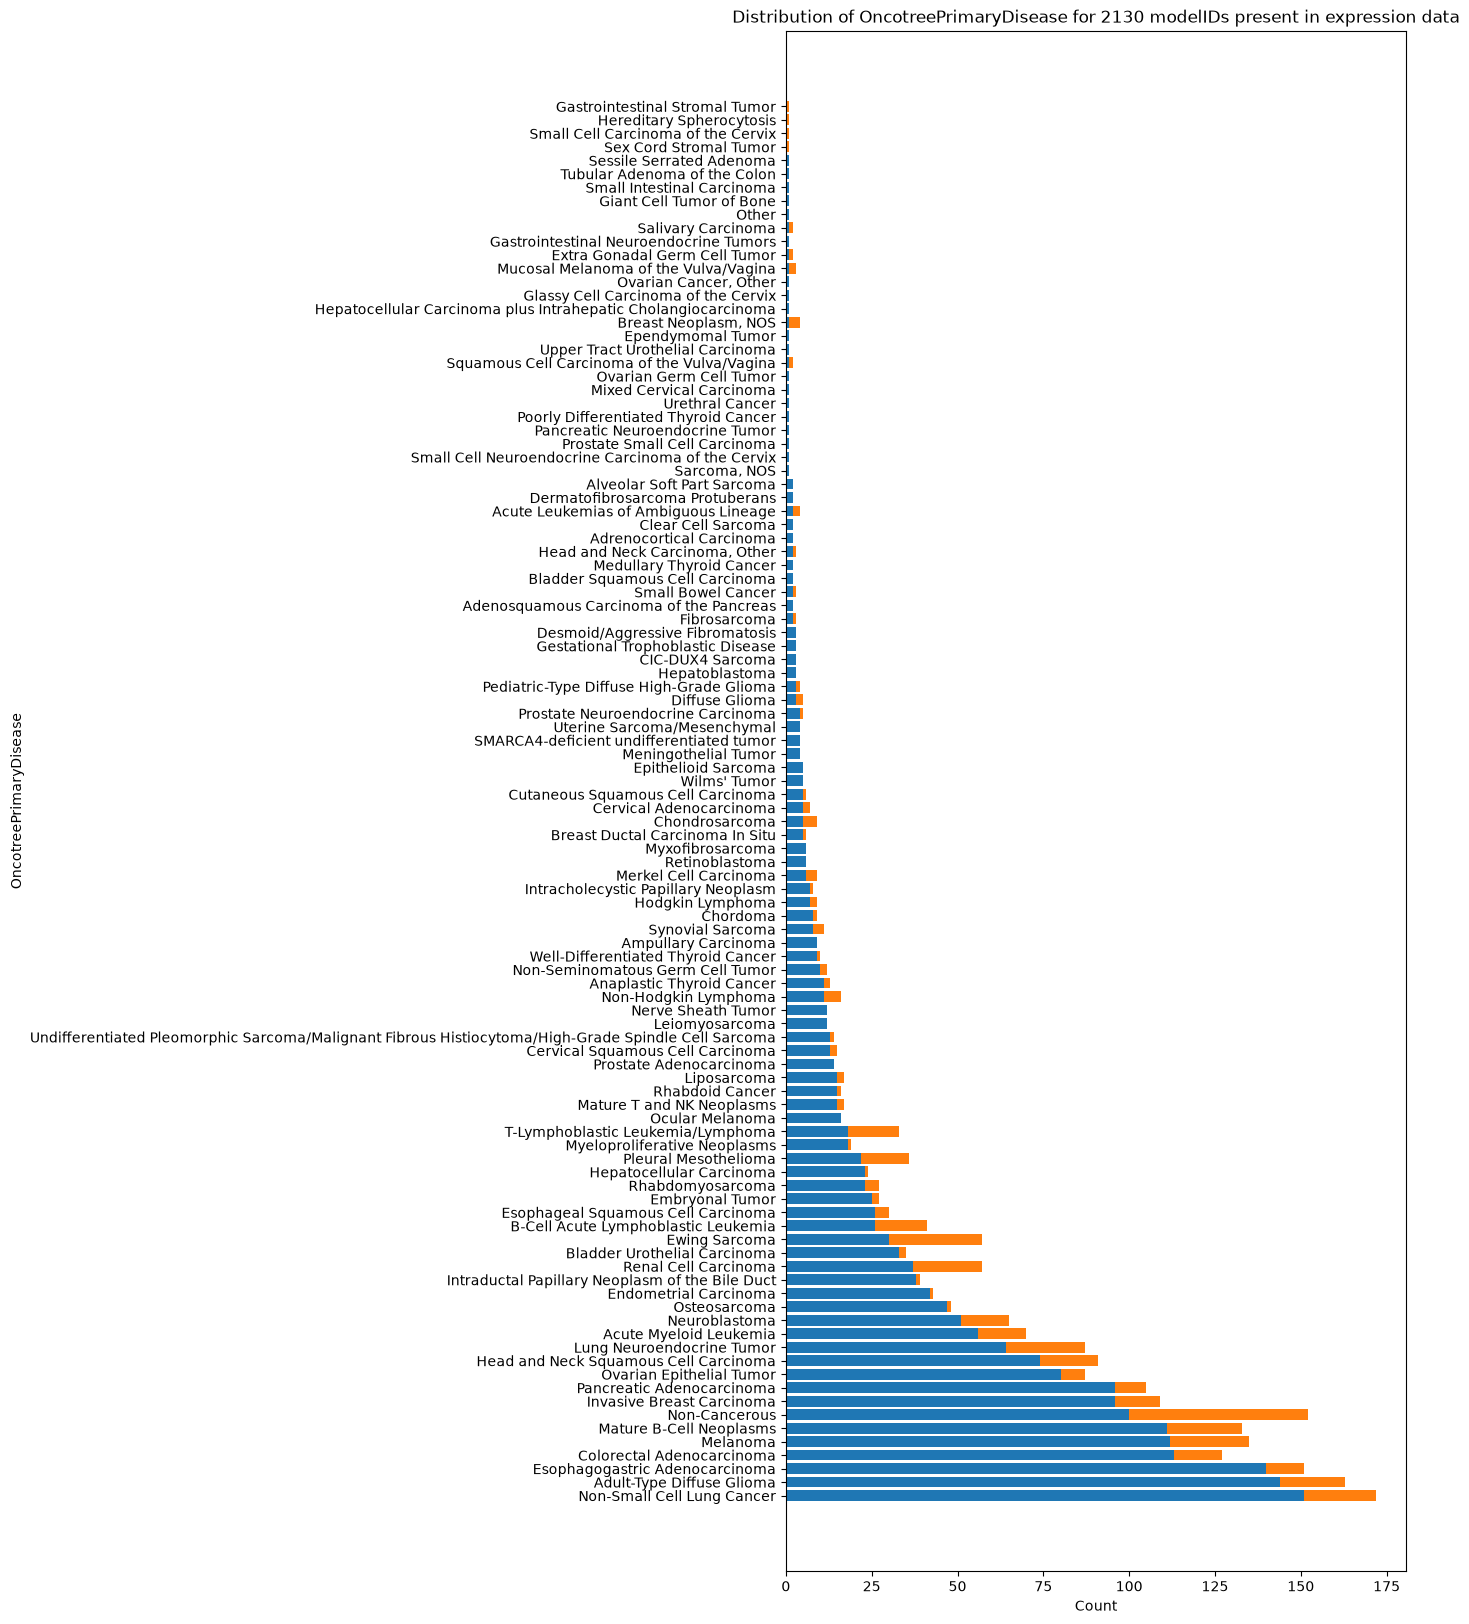

In [ ]:
# Visualizing the distribution of OncotreePrimaryDisease for the 2130 modelIDs that are present in expression data and the 424 modelIDs that are not present in expression data
fig, ax = plt.subplots(figsize=(8, 20))
ax.barh(value_counts_common.index, value_counts_common.values)
ax.barh(value_counts_diff.index, value_counts_diff.values, left=value_counts_common.reindex(value_counts_diff.index, fill_value=0).values)
plt.title("Distribution of OncotreePrimaryDisease for 2130 modelIDs present in expression data")
plt.xlabel("Count")
plt.ylabel("OncotreePrimaryDisease")
plt.show()

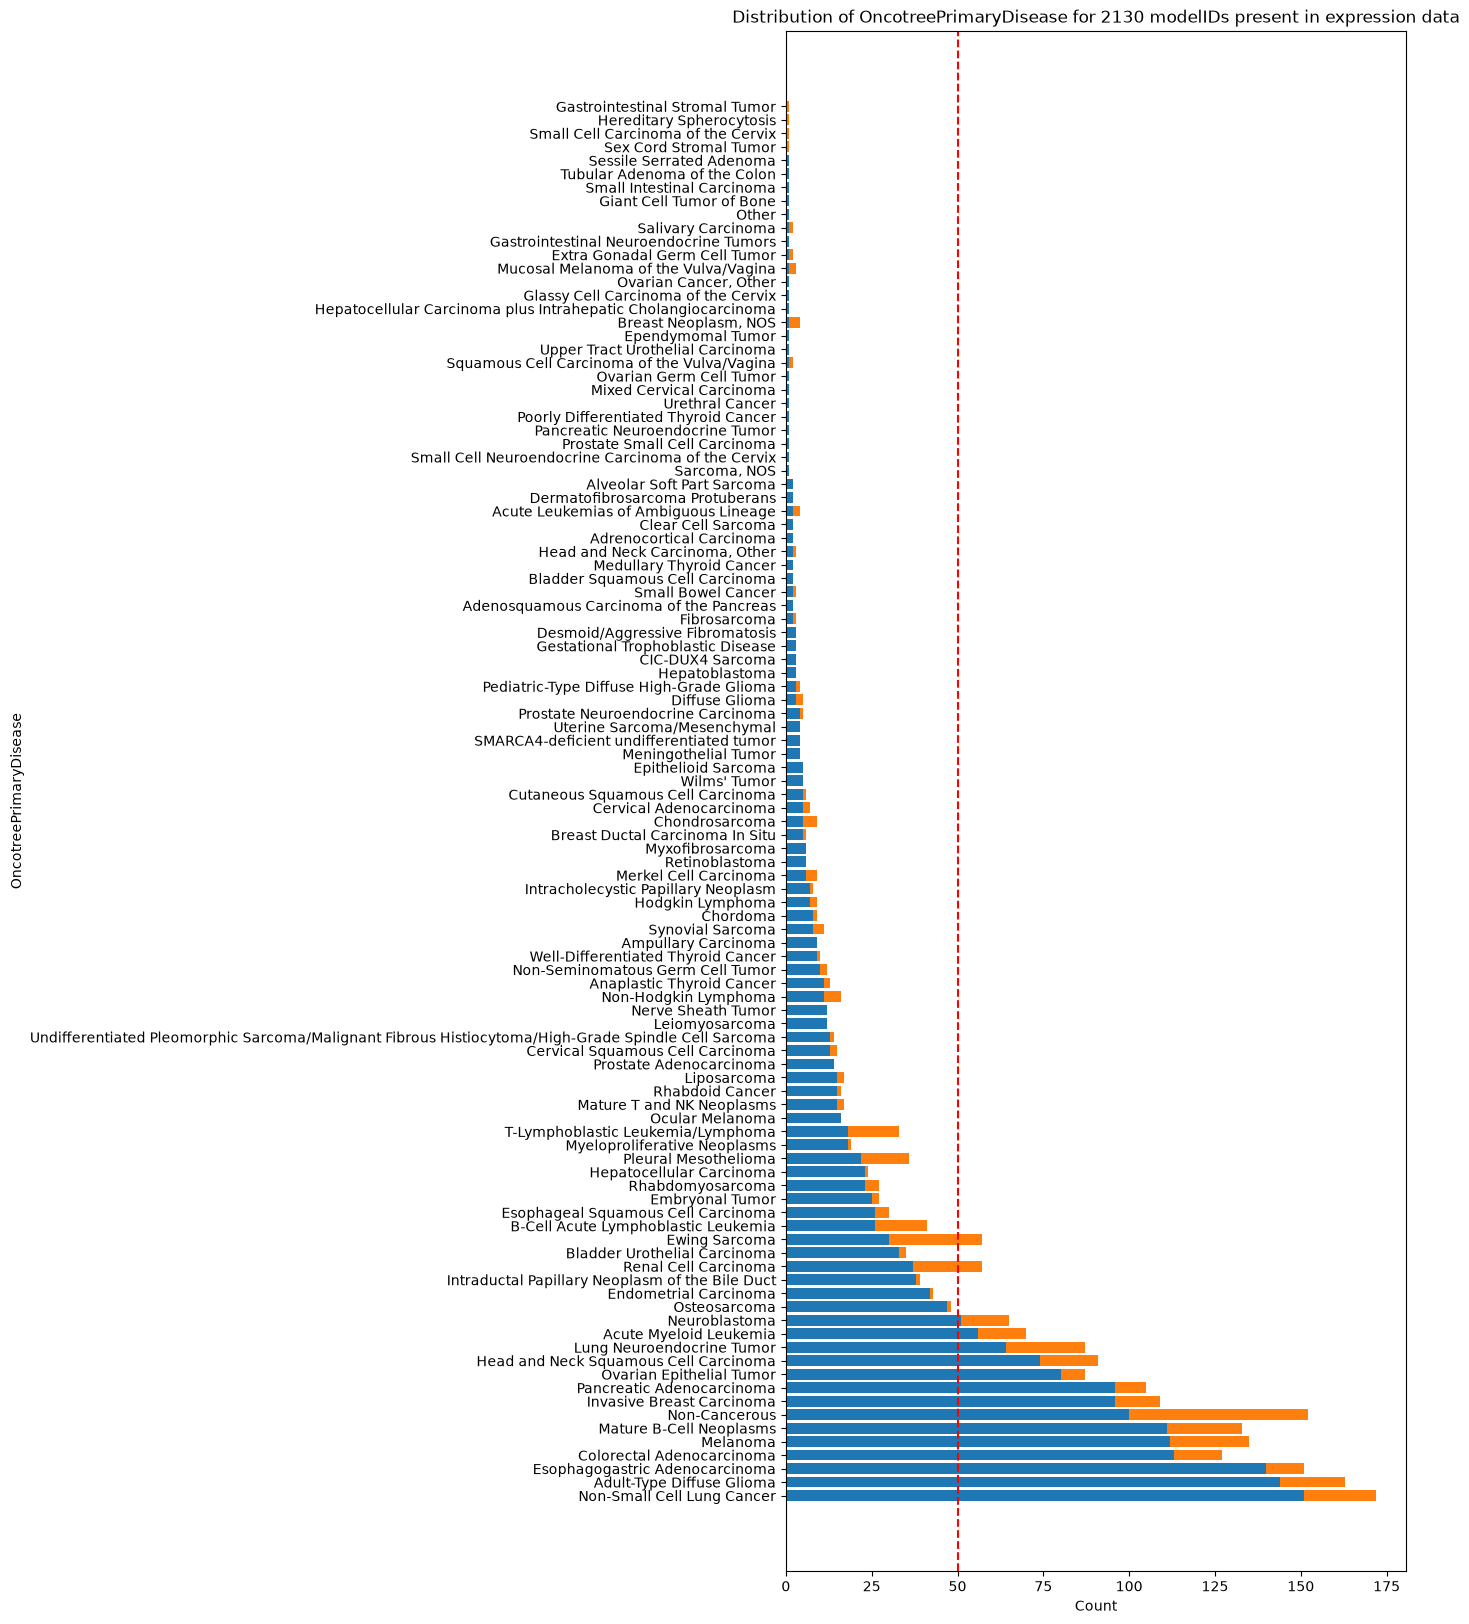

In [77]:
# Visualizing the distribution of OncotreePrimaryDisease for the 2130 modelIDs that are present in expression data and the 424 modelIDs that are not present in expression data
fig, ax = plt.subplots(figsize=(8, 20))
ax.barh(value_counts_common.index, value_counts_common.values)
ax.axvline(x=50, color='r', linestyle='--', label='Total Count in Expression Data')
ax.barh(value_counts_diff.index, value_counts_diff.values, left=value_counts_common.reindex(value_counts_diff.index, fill_value=0).values)
plt.title("Distribution of OncotreePrimaryDisease for 2130 modelIDs present in expression data")
plt.xlabel("Count")
plt.ylabel("OncotreePrimaryDisease")
plt.show()